# **Problem Statement**

## Business Context

A sales forecast is a prediction of future sales revenue based on historical data, industry trends, and the status of the current sales pipeline. Businesses use the sales forecast to estimate weekly, monthly, quarterly, and annual sales totals. A company needs to make an accurate sales forecast as it adds value across an organization and helps the different verticals to chalk out their future course of action.

Forecasting helps an organization plan its sales operations by region and provides valuable insights to the supply chain team regarding the procurement of goods and materials. An accurate sales forecast process has many benefits which include improved decision-making about the future and reduction of sales pipeline and forecast risks. Moreover, it helps to reduce the time spent in planning territory coverage and establish benchmarks that can be used to assess trends in the future.

## Objective

SuperKart is a retail chain operating supermarkets and food marts across various tier cities, offering a wide range of products. To optimize its inventory management and make informed decisions around regional sales strategies, SuperKart wants to accurately forecast the sales revenue of its outlets for the upcoming quarter.

To operationalize these insights at scale, the company has partnered with a data science firm—not just to build a predictive model based on historical sales data, but to develop and deploy a robust forecasting solution that can be integrated into SuperKart’s decision-making systems and used across its network of stores.

## Data Description

The data contains the different attributes of the various products and stores.The detailed data dictionary is given below.

- **Product_Id** - unique identifier of each product, each identifier having two letters at the beginning followed by a number.
- **Product_Weight** - weight of each product
- **Product_Sugar_Content** - sugar content of each product like low sugar, regular and no sugar
- **Product_Allocated_Area** - ratio of the allocated display area of each product to the total display area of all the products in a store
- **Product_Type** - broad category for each product like meat, snack foods, hard drinks, dairy, canned, soft drinks, health and hygiene, baking goods, bread, breakfast, frozen foods, fruits and vegetables, household, seafood, starchy foods, others
- **Product_MRP** - maximum retail price of each product
- **Store_Id** - unique identifier of each store
- **Store_Establishment_Year** - year in which the store was established
- **Store_Size** - size of the store depending on sq. feet like high, medium and low
- **Store_Location_City_Type** - type of city in which the store is located like Tier 1, Tier 2 and Tier 3. Tier 1 consists of cities where the standard of living is comparatively higher than its Tier 2 and Tier 3 counterparts.
- **Store_Type** - type of store depending on the products that are being sold there like Departmental Store, Supermarket Type 1, Supermarket Type 2 and Food Mart
- **Product_Store_Sales_Total** - total revenue generated by the sale of that particular product in that particular store


# **Installing and Importing the necessary libraries**

In [ ]:
#Installing the libraries with the specified versions
!pip install numpy==2.0.2 pandas==2.2.2 scikit-learn==1.6.1 matplotlib==3.10.0 seaborn==0.13.2 joblib==1.4.2 xgboost==2.1.4 requests==2.32.3 huggingface_hub==0.30.1 -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 301.8/301.8 kB 10.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 223.6/223.6 MB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.9/64.9 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 481.2/481.2 kB 25.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.32.3 which is incompatible.
gradio 5.50.0 requires huggingface-hub<2.0,>=0.33.5, but you have huggingface-hub 0.30.1 which is incompatible.
transformers 5.10.2 requires huggingface-hub<2.0,>=1.5.0, but you have huggingface-hub 0.30.1 which is incompatible.
google-adk 1.29.0 requires requests<3.0.0,>=2.32.4, but you have requests 2.32.3 which is incompatible.
diffusers 0.38.0 requires huggingface-hub<2.0,>=0.34.0, but you have huggi

**Note:**

- After running the above cell, kindly restart the notebook kernel (for Jupyter Notebook) or runtime (for Google Colab) and run all cells sequentially from the next cell.

- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in this notebook.

In [ ]:
import warnings
warnings.filterwarnings("ignore")

# Libraries to help with reading and manipulating data
import numpy as np
import pandas as pd

# For splitting the dataset
from sklearn.model_selection import train_test_split

# Libaries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Removes the limit for the number of displayed columns
pd.set_option("display.max_columns", None)
# Sets the limit for the number of displayed rows
pd.set_option("display.max_rows", 100)


# Libraries different ensemble classifiers
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor
)
from xgboost import XGBRegressor
from sklearn.tree import DecisionTreeRegressor

# Libraries to get different metric scores
from sklearn import metrics
from sklearn.metrics import (
    confusion_matrix,
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    mean_absolute_percentage_error
)


# To create the pipeline
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline,Pipeline

# To tune different models and standardize
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler,OneHotEncoder

# To serialize the model
import joblib

# os related functionalities
import os

# API request
import requests

# for hugging face space authentication to upload files
from huggingface_hub import login, HfApi

# **Loading the dataset**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# loading data into a pandas dataframe
data = pd.read_csv("/content/drive/MyDrive/SuperKart.csv")

**Creating a copy of data**

In [ ]:
# create a copy of the data to avoid permanent changes in original data
df = data.copy()

# **Data Overview**

**View the first 5 and last 5 rows of the dataset**

In [ ]:
# First 5 rows
df.head()

,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total
0,FD6114,12.66,Low Sugar,0.027,Frozen Foods,117.08,OUT004,2009,Medium,Tier 2,Supermarket Type2,2842.40
1,FD7839,16.54,Low Sugar,0.144,Dairy,171.43,OUT003,1999,Medium,Tier 1,Departmental Store,4830.02
2,FD5075,14.28,Regular,0.031,Canned,162.08,OUT001,1987,High,Tier 2,Supermarket Type1,4130.16
3,FD8233,12.10,Low Sugar,0.112,Baking Goods,186.31,OUT001,1987,High,Tier 2,Supermarket Type1,4132.18
4,NC1180,9.57,No Sugar,0.010,Health and Hygiene,123.67,OUT002,1998,Small,Tier 3,Food Mart,2279.36


In [ ]:
# Last 5 rows
df.tail()

,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Establishment_Year,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total
8758,NC7546,14.80,No Sugar,0.016,Health and Hygiene,140.53,OUT004,2009,Medium,Tier 2,Supermarket Type2,3806.53
8759,NC584,14.06,No Sugar,0.142,Household,144.51,OUT004,2009,Medium,Tier 2,Supermarket Type2,5020.74
8760,NC2471,13.48,No Sugar,0.017,Health and Hygiene,88.58,OUT001,1987,High,Tier 2,Supermarket Type1,2443.42
8761,NC7187,13.89,No Sugar,0.193,Household,168.44,OUT001,1987,High,Tier 2,Supermarket Type1,4171.82
8762,FD306,14.73,Low Sugar,0.177,Snack Foods,224.93,OUT002,1998,Small,Tier 3,Food Mart,2186.08


**Shape of the dataset**

In [ ]:
# checking no. of rows & columns in data
df.shape

(8763, 12)

**Observations:**

*   The dataset has 8763 rows and 12 columns.



**Column names in the dataset**

In [ ]:
# Display the column names of the dataset
df.columns

Index(['Product_Id', 'Product_Weight', 'Product_Sugar_Content',
       'Product_Allocated_Area', 'Product_Type', 'Product_MRP', 'Store_Id',
       'Store_Establishment_Year', 'Store_Size', 'Store_Location_City_Type',
       'Store_Type', 'Product_Store_Sales_Total'],
      dtype='object')

**Checking the types of attributes in the dataset**

In [ ]:
# checking attribute types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8763 entries, 0 to 8762
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Product_Id                 8763 non-null   object 
 1   Product_Weight             8763 non-null   float64
 2   Product_Sugar_Content      8763 non-null   object 
 3   Product_Allocated_Area     8763 non-null   float64
 4   Product_Type               8763 non-null   object 
 5   Product_MRP                8763 non-null   float64
 6   Store_Id                   8763 non-null   object 
 7   Store_Establishment_Year   8763 non-null   int64  
 8   Store_Size                 8763 non-null   object 
 9   Store_Location_City_Type   8763 non-null   object 
 10  Store_Type                 8763 non-null   object 
 11  Product_Store_Sales_Total  8763 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 821.7+ KB


**Observations:**

* **Product_Store_Sales_Total is the target variable** which indicates total revenue generated by the sale of a particular product in a specific store.
* ***Product_Id, Product_Sugar_Content, Product_Type, Store_Id, Store_Size, Store_Location_City_Type***, and ***Store_Type*** are categorical-type variables.
* All other variables are numerical in nature.
* ***Store_Establishment_Year*** is of numerical type but it represents the year in which the company was established, hence should be in datetime format.


**Checking for duplicates in the dataset**

In [ ]:
df.duplicated().sum() # get count of duplicates rows

np.int64(0)

**Observations:**

* There are no duplicates in the data.

In [ ]:
# checking for missing values
df.isnull().sum()

,0
Product_Id,0
Product_Weight,0
Product_Sugar_Content,0
Product_Allocated_Area,0
Product_Type,0
Product_MRP,0
Store_Id,0
Store_Establishment_Year,0
Store_Size,0
Store_Location_City_Type,0


- There are no missing values in both numerical and categorical columns.

**Defining the target variable & separating the numerical & categorical variables**



In [ ]:
# Define the target variable for the regression task
target = 'Product_Store_Sales_Total'

# List of categorical features in the dataset
categorical_features = df.select_dtypes(include='object').columns.tolist()

# List of numerical features in the dataset
numeric_features = df.select_dtypes(exclude='object').columns.tolist()

print("Categorical features:", categorical_features)
print("Numerical features:", numeric_features)

Categorical features: ['Product_Id', 'Product_Sugar_Content', 'Product_Type', 'Store_Id', 'Store_Size', 'Store_Location_City_Type', 'Store_Type']
Numerical features: ['Product_Weight', 'Product_Allocated_Area', 'Product_MRP', 'Store_Establishment_Year', 'Product_Store_Sales_Total']


**Statistical summary of the data**

In [ ]:
# getting descriptive statistics of the numerical data & transpose
df[numeric_features].describe().T

,count,mean,std,min,25%,50%,75%,max
Product_Weight,8763.0,12.653792,2.217320,4.000,11.150,12.660,14.180,22.000
Product_Allocated_Area,8763.0,0.068786,0.048204,0.004,0.031,0.056,0.096,0.298
Product_MRP,8763.0,147.032539,30.694110,31.000,126.160,146.740,167.585,266.000
Store_Establishment_Year,8763.0,2002.032751,8.388381,1987.000,1998.000,2009.000,2009.000,2009.000
Product_Store_Sales_Total,8763.0,3464.003640,1065.630494,33.000,2761.715,3452.340,4145.165,8000.000


**Observations:**

*  **Product_Weight:**
    *  The average product weight is 12.65 units.
    *  The mean (12.65) and median (12.66) are almost identical, which indicates a symmetric distribution.

*  **Product_Allocated_Area:**
    *  On average a product acquires 6.9% of the store display area.
    *  The maximum allocation is 29.8% which indicates some products acquire a large shelf space compared to others.

*  **Product_MRP:**
    *  The average price is Rs 147. The minimum and maximum prices are Rs 31 and Rs 266, respectively.
    *  The mean (147) and median (146) are very close indicating a symmetric distribution.

*  **Store_Establishment_Year:**
    *  The stores were established between 1987 and 2009.
    *  Most of the stores were established in 2009.

*  **Product_Store_Sales_Total (Target variable):**
    *  The sales range between Rs 33-8000. The average sales revenue is Rs 3464.







In [ ]:
# Generate summary statistics for categorical features
cat_cols = [col for col in categorical_features if col != 'Product_Id'] # excluding 'Product_Id' as it is an identifier

df[cat_cols].describe().T

,count,unique,top,freq
Product_Sugar_Content,8763,4,Low Sugar,4885
Product_Type,8763,16,Fruits and Vegetables,1249
Store_Id,8763,4,OUT004,4676
Store_Size,8763,3,Medium,6025
Store_Location_City_Type,8763,3,Tier 2,6262
Store_Type,8763,4,Supermarket Type2,4676


- The **Product_Id** attribute was not considered as it serves only as a unique identifier and does not provide meaningfulo information for the analysis and modeling.

- **Low sugar** products are the most common products (**~ 55.7%**) in the datasets.

- **Fruits and Vegetables** is the most frequent food category in the stores.

- The dataset contains data from four different stores in the as is evident from the no. of **Store IDs** with the highest number of observations (**~ 53.4%**) from **OUT004**.

- Most of the stores are **medium-sized**.

- The majority of the stores are located in **Tier 2 cities**

- The most common **Store_Type** is **Supermarket Type2** (**~ 53.4%**.

**Checking the distribution of categories in categorical variables**



In [ ]:
for col in cat_cols:
    print(df[col].value_counts(normalize=True))
    print("*" * 50)

Product_Sugar_Content
Low Sugar    0.557457
Regular      0.256875
No Sugar     0.173342
reg          0.012325
Name: proportion, dtype: float64
**************************************************
Product_Type
Fruits and Vegetables    0.142531
Snack Foods              0.131119
Frozen Foods             0.092548
Dairy                    0.090836
Household                0.084446
Baking Goods             0.081707
Canned                   0.077257
Health and Hygiene       0.071665
Meat                     0.070524
Soft Drinks              0.059226
Breads                   0.022823
Hard Drinks              0.021226
Others                   0.017232
Starchy Foods            0.016090
Breakfast                0.012096
Seafood                  0.008673
Name: proportion, dtype: float64
**************************************************
Store_Id
OUT004    0.533607
OUT001    0.180988
OUT003    0.153943
OUT002    0.131462
Name: proportion, dtype: float64
***********************************************

**Observations:**

*  **Product_Sugar_Content:**
    *  The most common category is of *Low Sugar* products as it constitutes 55.75% of the dataset.
    *  The category "*reg*" represents only 1.23% of products but it appears a data quality issue (most likely it's a representation of Regular cateogry).

*  **Product_Type:**
    *  The product types are diverse.
    *  *Fruits and Vegetables* (14.25%) is the most common product category followed by *Snack Foods* (13.11%).
    
*  **Store_ID:**
    *  One store, *OUT004*, accounts for almost half (53.36%) of the observations.
    *  The other stores contribute between 13-18%.

*  **Store_Size:**
    *  The *medium size stores* account for 68.76% of observations dominating the sales.

*  **Store_Location_City_Type:**
    *  The dataset is predominated by the stores in Tier 2 cities accounting for 71.46% of records.

*  **Store_Type:**
    *  *Supermarket Type 2* highly dominates the data contributing to 53.36% of observations.
    *  *Food Marts* contribute 13.15% records.





In [ ]:
# Generate summary statistics for the target variable
df[target].describe()

,Product_Store_Sales_Total
count,8763.000000
mean,3464.003640
std,1065.630494
min,33.000000
25%,2761.715000
50%,3452.340000
75%,4145.165000
max,8000.000000


**Observations:**
*   The mean (3464) and median (3452.34) are very close suggesting that the distribution of the target variable is alsmost symmetric.
*   The difference in the minimum (33) and maximum (8000) sales value indicate the huge variability in the sales accross the stores.
*   Most sales values lie between 2761.71-4145.17.




# **Exploratory Data Analysis (EDA)**

**Correcting inconsistency in the Product_Sugar_Content**



In [ ]:
# replacing reg with Regular category in Product_Sugar_Content
df['Product_Sugar_Content'] = df['Product_Sugar_Content'].replace('reg', 'Regular')

In [ ]:
# checking the Product_Sugar_Content after cleanup
df['Product_Sugar_Content'].value_counts()

,count
Product_Sugar_Content,
Low Sugar,4885
Regular,2359
No Sugar,1519


- *Reg* is not a category and was replaced with Regular category.

- The **Product_Sugar_Content** has 3 categories:
  - Low Sugar
  - Regular
  - No Sugar

## **Univariate Analysis**

**Check the distribution of the target variable**

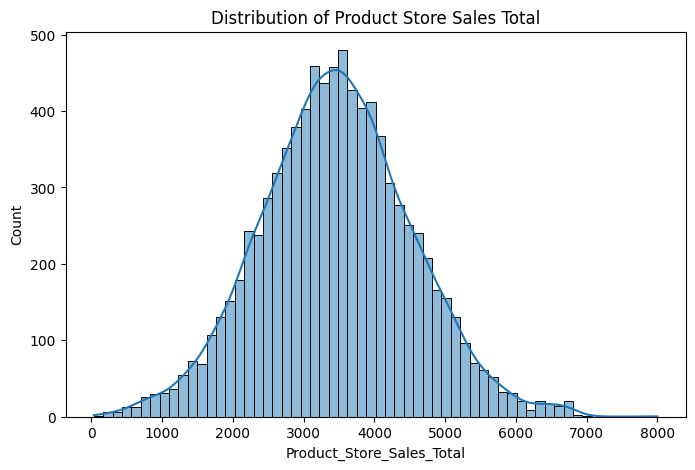

In [ ]:
# Check the distribution of the target variable
plt.figure(figsize=(8,5))
sns.histplot(df['Product_Store_Sales_Total'], kde=True)
plt.title('Distribution of Product Store Sales Total')
plt.show()

**Observations**

- ***Product_Store_Sales_Total*** appears to be **normally distributed**.

**Univariate Analysis of Numeric Attributes - Histograms**




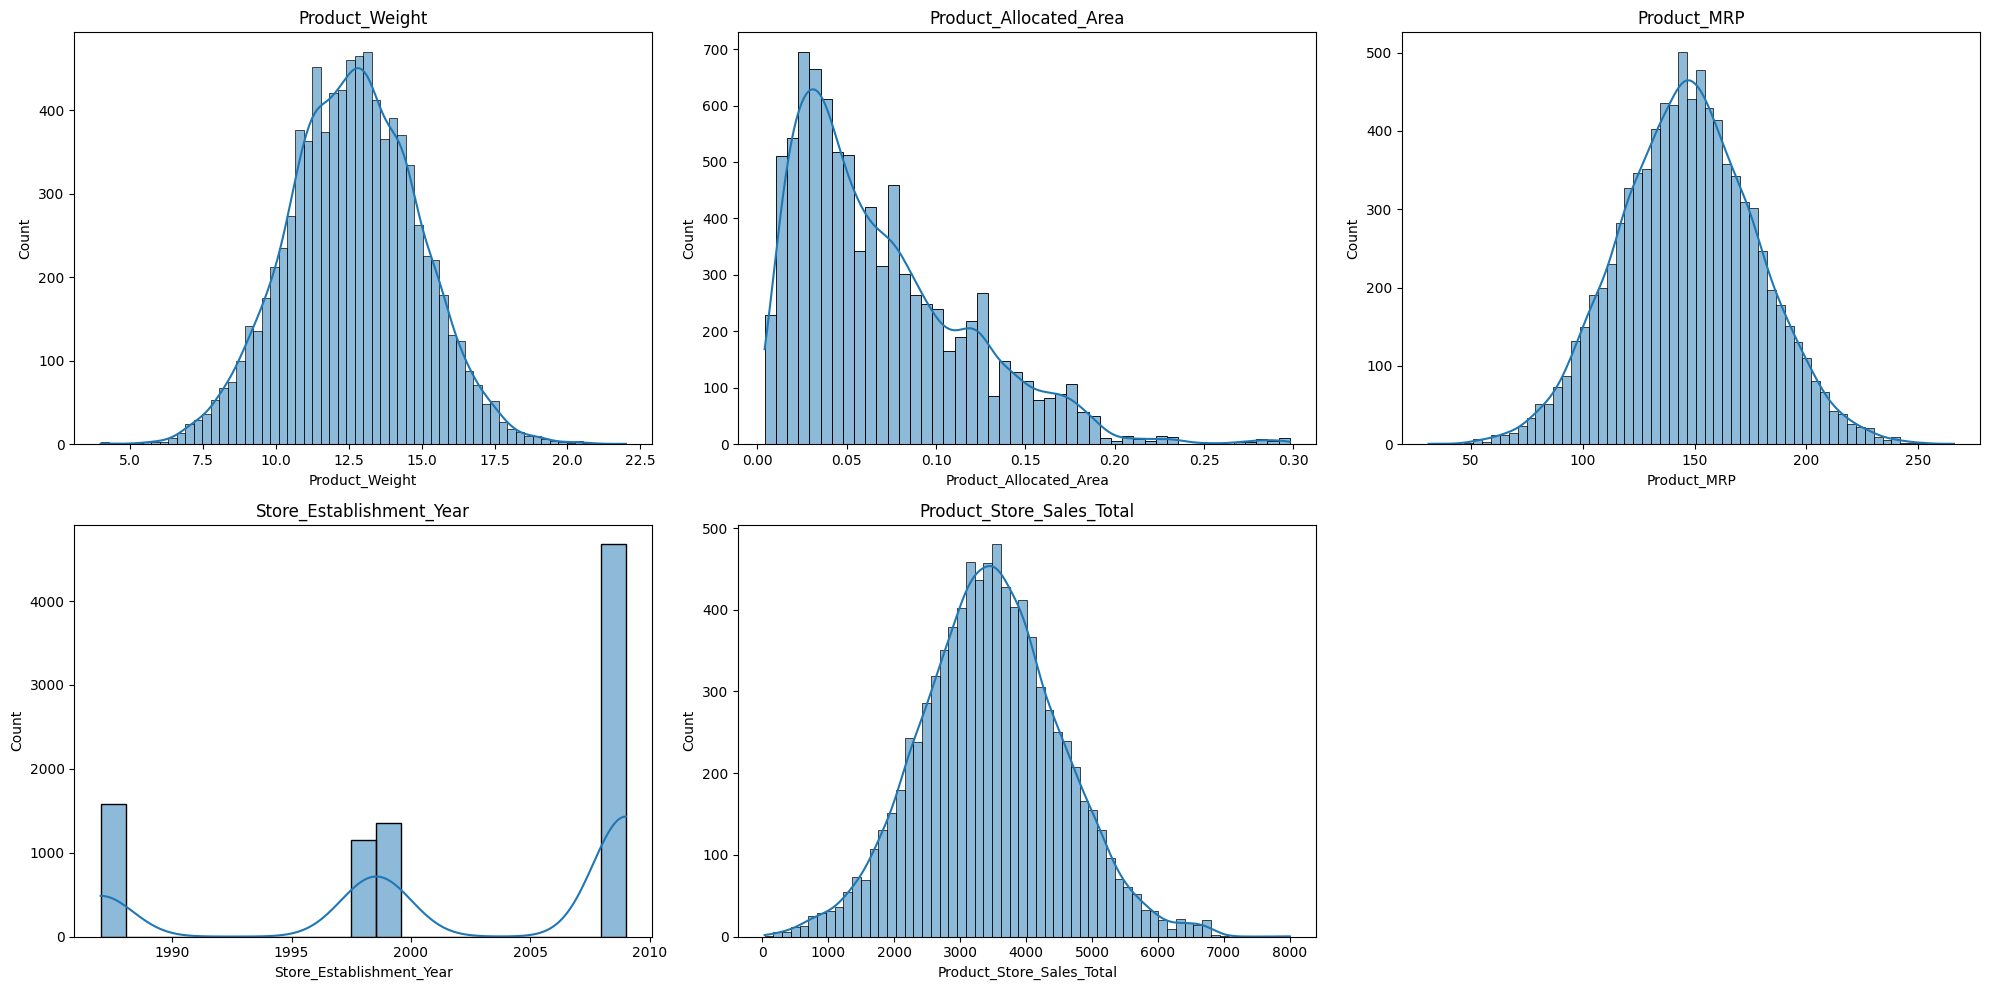

In [ ]:
# defining the figure size
plt.figure(figsize=(20, 10))

# creating histograms
for i, col in enumerate(numeric_features):
  plt.subplot(2, 3, i+1)
  sns.histplot(data = df, x = col, kde=True)
  plt.title(col)

plt.tight_layout()
plt.show()


**Observations:**

*  ***Product_Weight, Product_MRP and Product_Store_Sales_Total*** demonstrate approximately **normal distributions**.
*  ***Product_Allocated_Area*** is **positively skewed** indicating that although most of the prodcuts need a small shelf space, some require a substantially large space.
*  ***Store_Establishment_Year*** shows distinct peaks corresponding to the specific store opening years with **large spikes** around the year **2009**.






**Univariate Analysis of Categorical Attributes - Countplots**

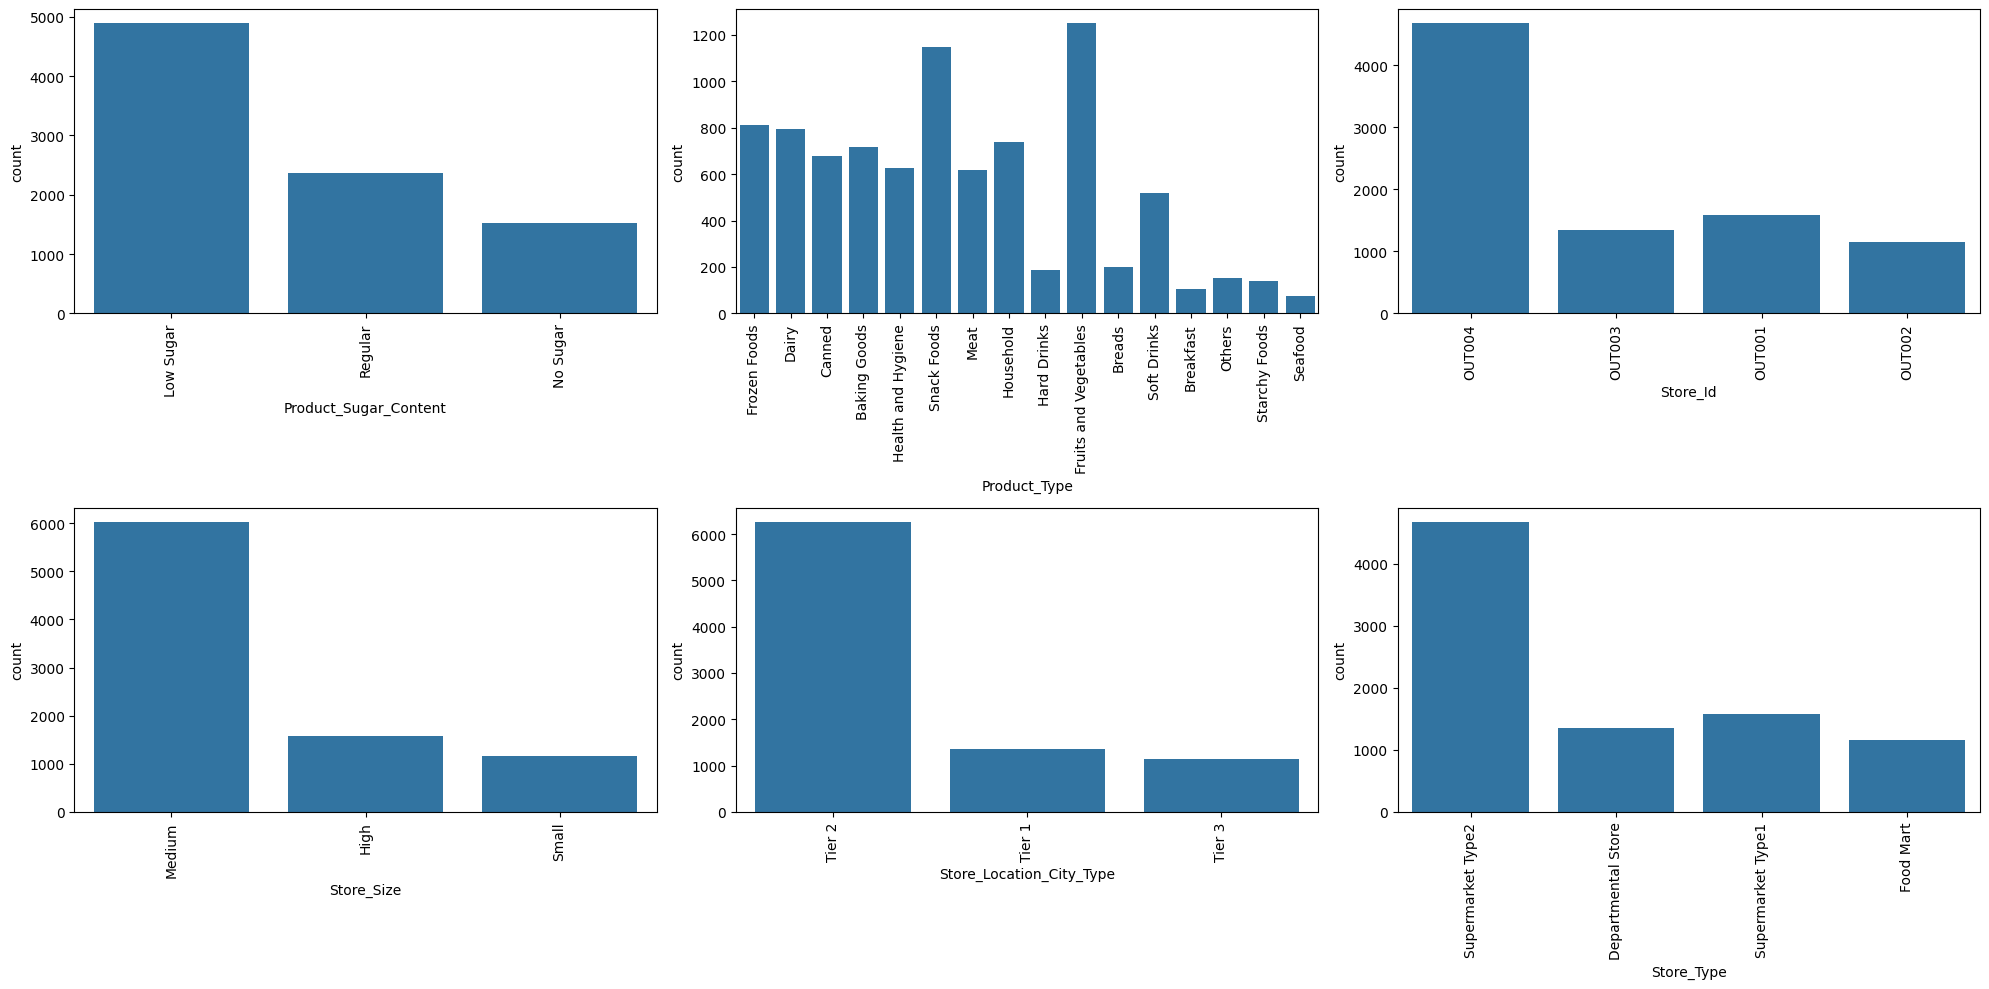

In [ ]:
# defining the figure size
plt.figure(figsize=(20, 10))

# creating countplot
for i, col in enumerate(cat_cols):
  plt.subplot(2, 3, i+1)
  sns.countplot(data = df, x = col)
  plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

**Observations:**

*  ***Low Sugar products, Fruits and Vegetables, Medium-sized stores, Tier 2 cities***, and ***Supermarket Type 2*** outlets clearly **dominate** the dataset.

* There seems to be a direct mapping between **Store_Type** and **Store_ID**.






**Store_ID vs Store_Type Relationship**

In [ ]:
# exploring the mapping between store type and store ID
pd.crosstab(df['Store_Id'], df['Store_Type'])

Store_Type,Departmental Store,Food Mart,Supermarket Type1,Supermarket Type2
Store_Id,,,,
OUT001,0,0,1586,0
OUT002,0,1152,0,0
OUT003,1349,0,0,0
OUT004,0,0,0,4676


**Observations:**

- A one-to-one mapping can be seen in Store_ID and Store_Type.

## **Bivariate Analysis**

**Scatter Plots to show the relationship between numerical variables**

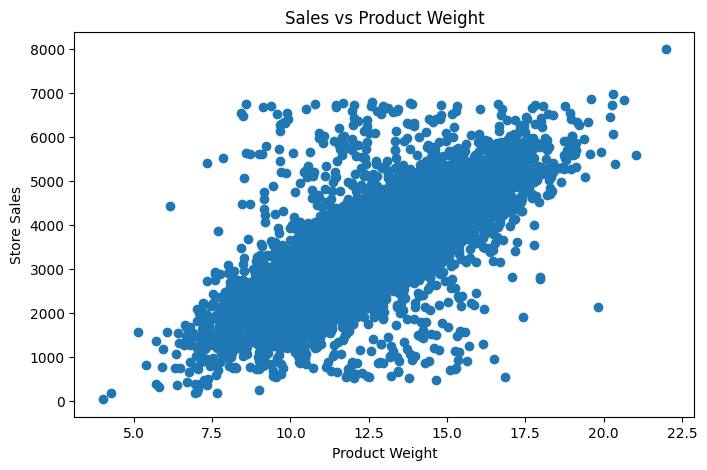

In [ ]:
# Product Weight vs Sales
plt.figure(figsize=(8,5))
plt.scatter(
    df['Product_Weight'],
    df['Product_Store_Sales_Total'])
plt.xlabel("Product Weight")
plt.ylabel("Store Sales")
plt.title("Sales vs Product Weight")
plt.show()

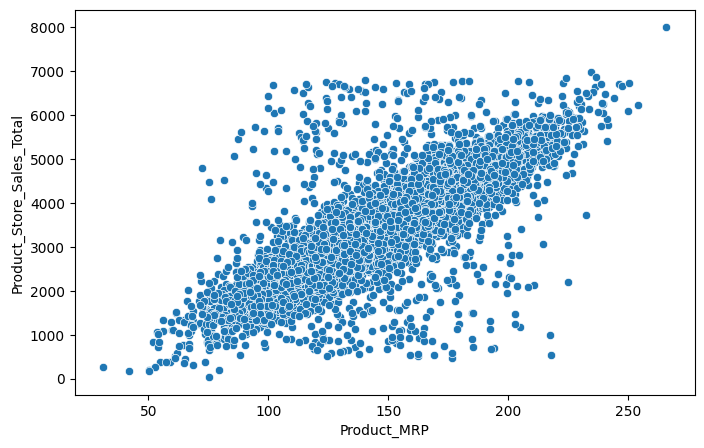

In [ ]:
# Product MRP vs Sales
plt.figure(figsize=(8,5))
sns.scatterplot(
    data=df,
    x='Product_MRP',
    y='Product_Store_Sales_Total'
)
plt.show()

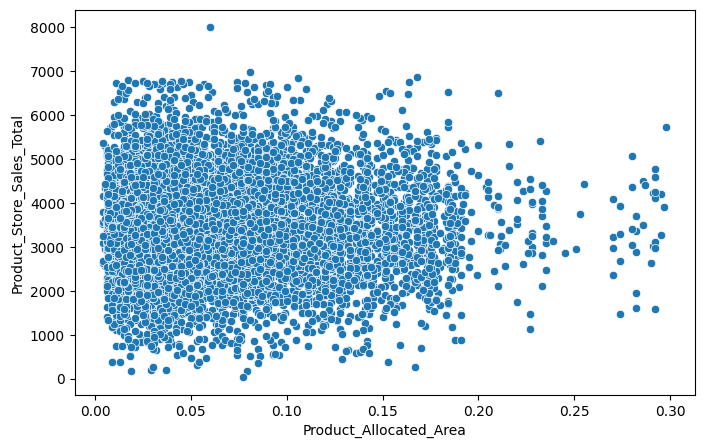

In [ ]:
# Product Allocated Area vs Sales
plt.figure(figsize=(8,5))
sns.scatterplot(
    data=df,
    x='Product_Allocated_Area',
    y='Product_Store_Sales_Total'
)
plt.show()

**Observations from Scatter Plots:**

- **Product_Weight vs Product_Store_Sales_Total**

  - A positive relationship can be seen between **Product_Weight** and **Product_Store_Sales_Total**.

  - Products with higher weights tend to achieve higher sales.

- **Product_Weight vs Product_Store_Sales_Total**

    - The products with higher MRP tend to generate more sales indicating a **positive relationship** between **Product_MRP** and **Product_Store_Sales_Total**.

- **Product_Allocated_Area vs Product_Store_Sales_Total**

  - There appears to be a **weak relationship** between the **Product_Allocated_Area** and **Product_Store_Sales_Total**.

  - Products with both low and high Product_Allocated_Area exhibit a wide range of sales values.

**Correlation Heatmap to examine linear relationships between numerical variables**

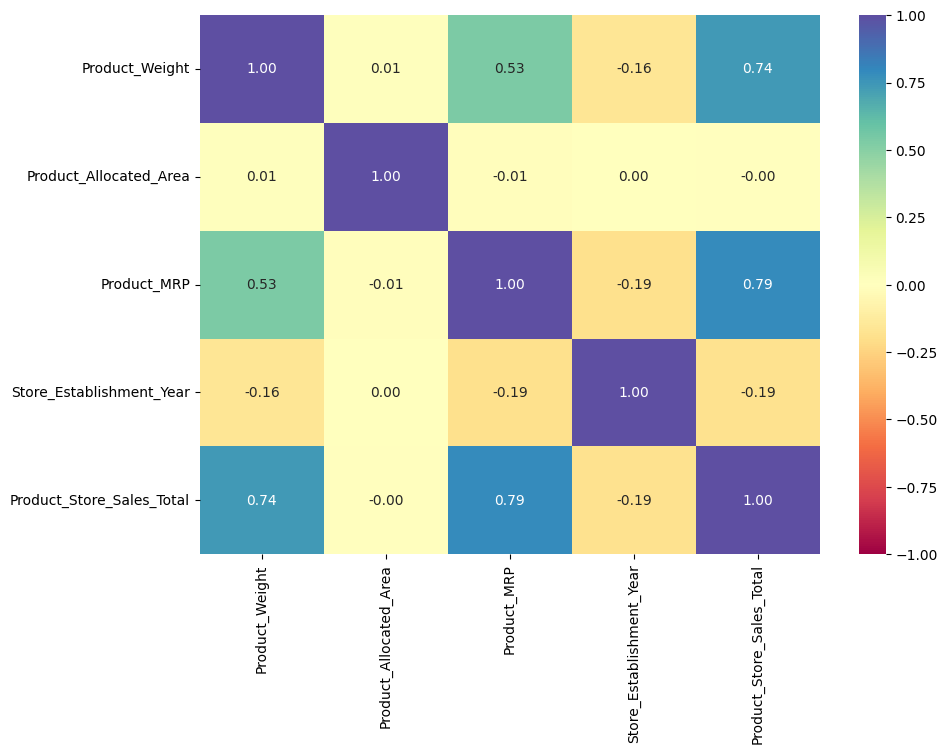

In [ ]:
# defining the figure size
plt.figure(figsize=(10, 7))

# plotting the correlation heatmap
sns.heatmap(df.corr(numeric_only = True), annot=True, vmin=-1, vmax=1, fmt='0.2f', cmap='Spectral');

**Observation:**

* ***Product_MRP*** appears to be the **most influential feature** with a **high correlation value of 0.79** with *sales*.
* ***Product_Weight*** also has a **high correlation** of 0.74 with *sales* suggesting that heavier products generate high revenue.
* The **negative correlation** value of -0.19 of **Store_Establishment_Year** indicates that store maturity doesn't have much impact on sales.
* ***Product_Allocated_Area*** **doesn't have any association** with sales as is evident from correlation value 0.
* There is a **moderate positive correlation** 0.53 between ***Product_MRP*** and ***Product_Weight*** indicating heavier products have higher price.

**Box Plots - Categorical variables vs Target variable**

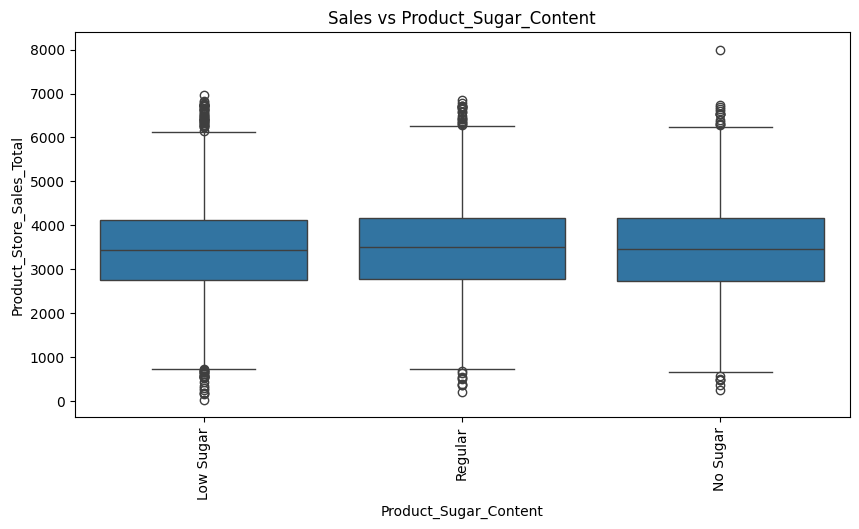

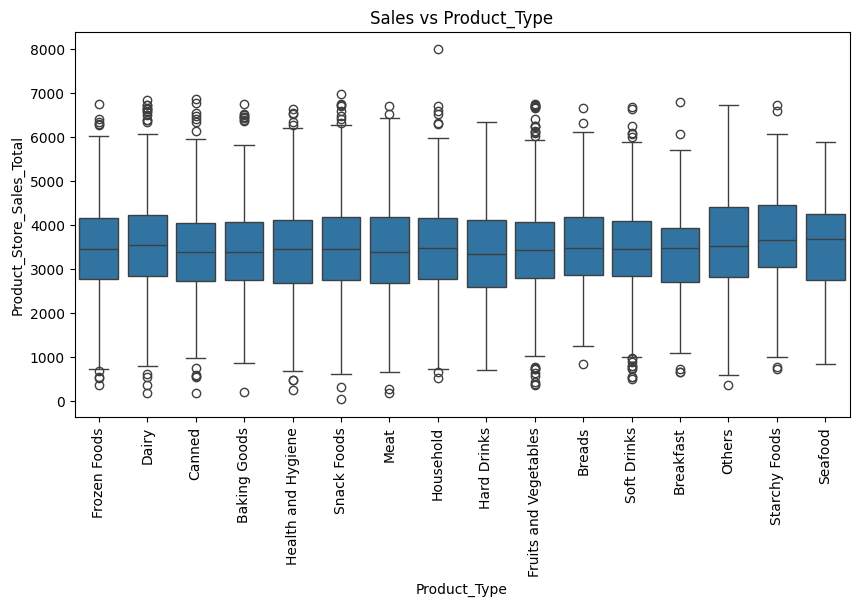

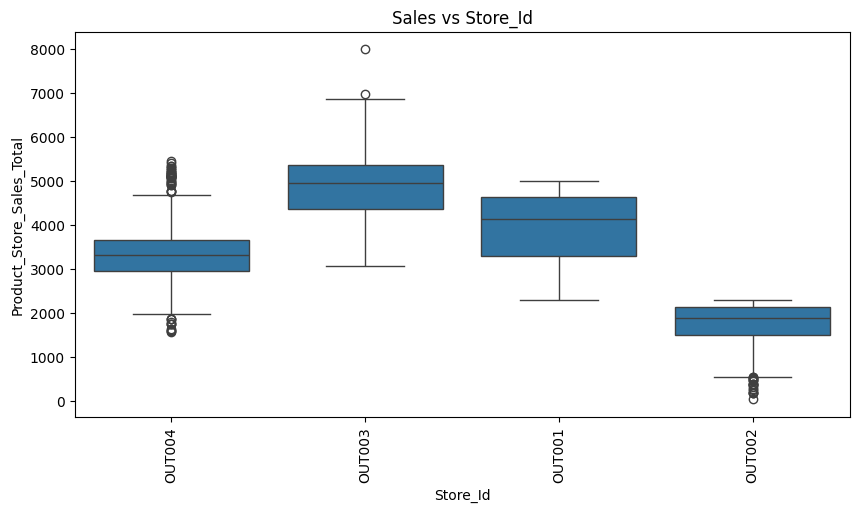

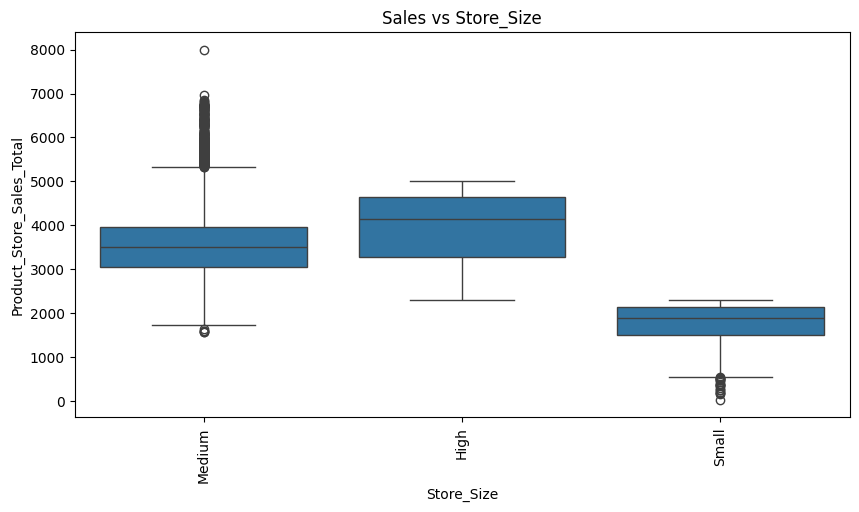

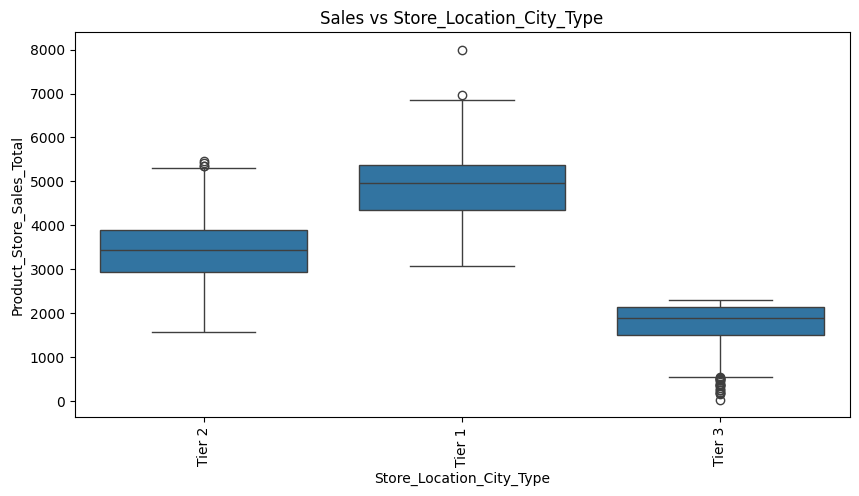

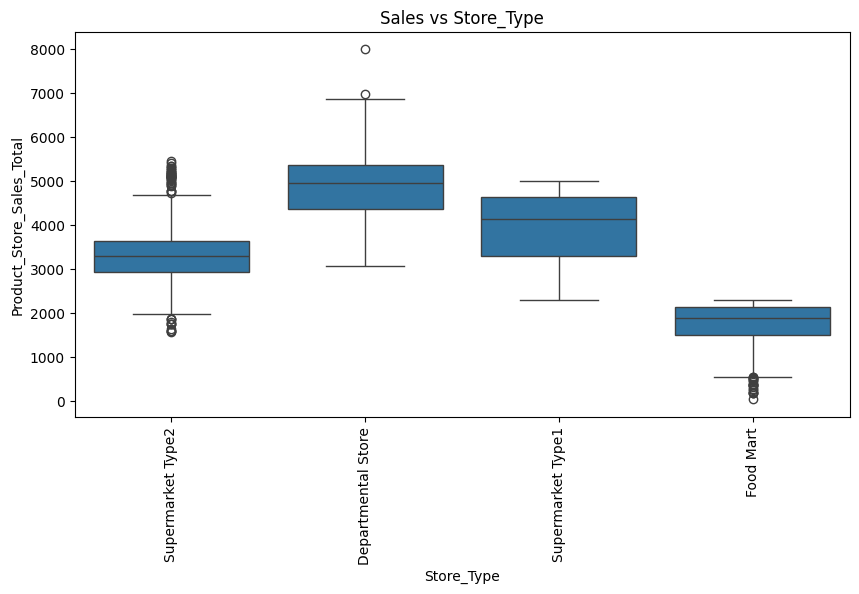

In [ ]:
# Boxplots for Categorical variables  vs Sales
for col in cat_cols:
    plt.figure(figsize=(10,5))
    sns.boxplot(
        x=col,
        y='Product_Store_Sales_Total',
        data=df
    )
    plt.xticks(rotation=90)
    plt.title(f'Sales vs {col}')
    plt.show()

**Observations:**

**Product_Sugar_Content vs Product_Store_Sales_Total**
  * The box plots shows that the **product sugar content does not have a significant impact on sales** as the distribution of sales is highly similar across Low Sugar, Regular, and No Sugar products.
  * A few outliers are present in all the categories with an extreme outlier at 8000 in No sugar products.


**Product_Type vs Product_Store_Sales_Total**
  * The box plots shows that the **distribution of sales is overall similar** across all product types.
  * **Seafood, Starchy foods** and **Others** show **slightly higher median** sales compared to other products.
  * Most of the products show **outliers** indicating that some products are extremely high performing. **Household** has an **extreme outlier** near 8000.
  
**Store_ID vs Product_Store_Sales_Total**
  * The best performing store is **OUT003** with the **highest overall sales** and **highest median** value.
  * **OUT002** is the **weakest-performing** store with the lowest median and overall sales.

**Store_Size vs Product_Store_Sales_Total**
  * **High-sized** stores generate **highest revenue** amongst  all the categories.
  * A large number of **outliers** can be seen in **medium-sized** stores with an extreme outlier at 8000.

**Store_Location_City_Type vs Product_Store_Sales_Total**
  * The stores located in **Tier 1 cities** stores generate **highest revenue** followed by **Tier 2**.
  * An extreme outlier at 8000 can be seen in Teir 1 cities.

**Store_Type vs Product_Store_Sales_Total**
  * **Departmental Stores** appear to be highest contributor for sales followed by **Supermarket Type 1**.
  * There is an extreme outlier at 8000 in **Departmental Stores**.
  * **Food Marts** have the **lowest median and overall sales**.

### **Key Insights from EDA**

*   The count plots demonstrate that the dataset is dominated by **Low Sugar products, Fruits and Vegetables, Medium-sized stores, Tier 2 cities**, and **Supermarket Type 2 outlets**, suggesting that these segments play a major role in business operations.

*   The correlation analysis reveal that **Product_MRP** and **Product_Weight** have a **positive relationship** with Product_Store_Sales_Total, indicating that these variables are important drivers of sales.

*   The box plots show that **Store_Size, Store_ID, Store_Location_City_Type** and **Store_Type** have a **strong influence** on sales. A clear difference can be seen in the distribution of sales across different categories in these variables.

*   Several **outliers** were observed in many variables which might actually be exceptionally performing products and stores.





# **Data Preprocessing**

**Convert Store_Establishment_Year from int to datetime format**

In [ ]:
df['Store_Establishment_Year'] = pd.to_datetime(df['Store_Establishment_Year'], format='%Y')

# check data type of Store_Establishment_Year
df['Store_Establishment_Year'].dtype

dtype('<M8[ns]')

**Outlier detection & Treatment**

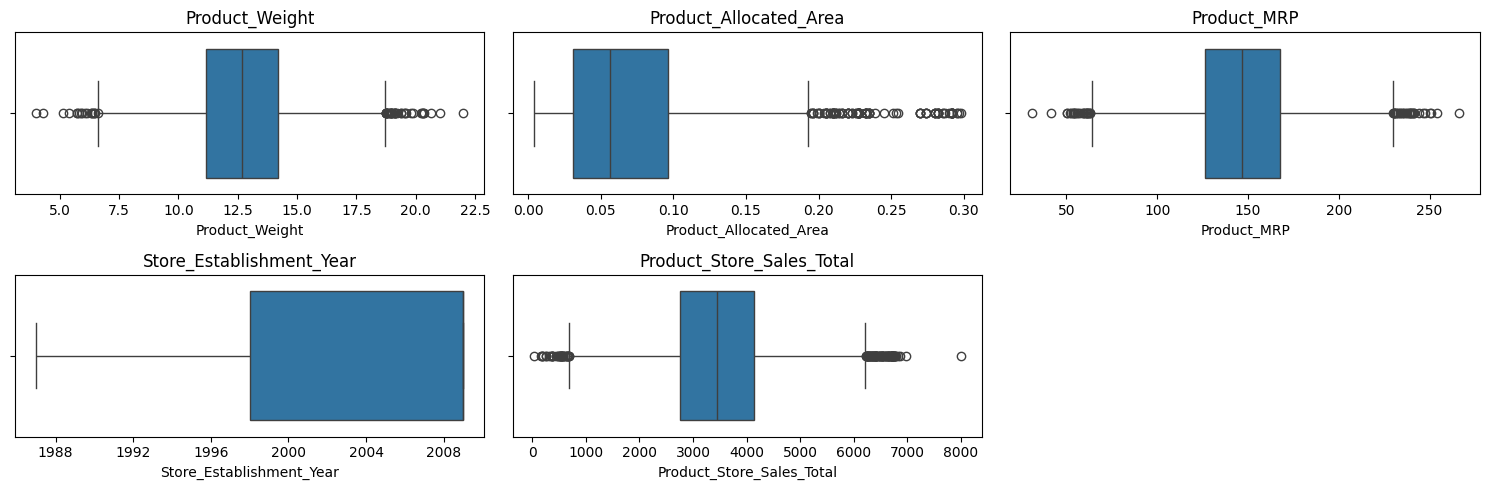

In [ ]:
# defining the figure size
plt.figure(figsize=(15, 5))

# creating histograms
for i, col in enumerate(numeric_features):
  plt.subplot(2, 3, i+1)
  sns.boxplot(data = df, x = col)
  plt.title(col)

plt.tight_layout()
plt.show()

**Observations:**
* Outliers are present in **Product_Weight, Product_Allocated_Area, Product_MRP**, and **Product_Store_Sales_Total**.
* These outliers can be genuine business scenarios as in retail sales dataset, there can be products of different sizes, weights and price points leading to variation in sales performance.


***All the outliers were retained because these likely represent real-world values.***

**Dropping the columns having unique values**




In [ ]:
df['Product_Id'].nunique()

8763

* Since all the values in case_id column are unique, it will not contribute in model predictions and thus can be dropped.

In [ ]:
# Dropping ID column
df.drop(columns = 'Product_Id', axis=1, inplace=True)

### **Feature Engineering**

**Calculate store age from store establishment year**


In [ ]:
# calculate store age from current year
df['store_age'] = 2026 - df['Store_Establishment_Year']
df.drop('Store_Establishment_Year', axis=1, inplace=True) # drop original column
df.head() # check the data


,Product_Id,Product_Weight,Product_Sugar_Content,Product_Allocated_Area,Product_Type,Product_MRP,Store_Id,Store_Size,Store_Location_City_Type,Store_Type,Product_Store_Sales_Total,store_age
0,FD6114,12.66,Low Sugar,0.027,Frozen Foods,117.08,OUT004,Medium,Tier 2,Supermarket Type2,2842.40,17
1,FD7839,16.54,Low Sugar,0.144,Dairy,171.43,OUT003,Medium,Tier 1,Departmental Store,4830.02,27
2,FD5075,14.28,Regular,0.031,Canned,162.08,OUT001,High,Tier 2,Supermarket Type1,4130.16,39
3,FD8233,12.10,Low Sugar,0.112,Baking Goods,186.31,OUT001,High,Tier 2,Supermarket Type1,4132.18,39
4,NC1180,9.57,No Sugar,0.010,Health and Hygiene,123.67,OUT002,Small,Tier 3,Food Mart,2279.36,28


**Observations:**

* The original column, 'Store_Establishment_Year' was dropped.
* A new column, 'store_age' was added.

### **Data preparation for modeling**

**Defining the explanatory (independent) and response (dependent) variables**

In [ ]:
X = df.drop(["Product_Store_Sales_Total"], axis=1) # Features
y = df["Product_Store_Sales_Total"] # Target variable

**Creating train and test sets**





In [ ]:
# Splitting the data into 80% temporary set and 20% test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, random_state=42)

In [ ]:
# Number of rows in train & test sets
print("Number of instances in train set:", X_train.shape[0])
print("Number of instances in test set:", X_test.shape[0])

Number of instances in train set: 7010
Number of instances in test set: 1753


In [ ]:
# Create a preprocessing pipeline for categorical features

preprocessor = make_column_transformer(
    (
        Pipeline([
            ('encoder', OneHotEncoder(handle_unknown='ignore'))
        ]),
        cat_cols
    ),
    remainder='passthrough'
)

# **Model Building**

## Define functions for Model Evaluation

In [ ]:
# function to compute adjusted R-squared
def adj_r2_score(predictors, targets, predictions):
    r2 = r2_score(targets, predictions)
    n = predictors.shape[0]
    k = predictors.shape[1]
    return 1 - ((1 - r2) * (n - 1) / (n - k - 1))


# function to compute different metrics to check performance of a regression model
def model_performance_regression(model, predictors, target):
    """
    Function to compute different metrics to check regression model performance

    model: regressor
    predictors: independent variables
    target: dependent variable
    """

    # predicting using the independent variables
    pred = model.predict(predictors)

    r2 = r2_score(target, pred)  # to compute R-squared
    adjr2 = adj_r2_score(predictors, target, pred)  # to compute adjusted R-squared
    rmse = np.sqrt(mean_squared_error(target, pred))  # to compute RMSE
    mae = mean_absolute_error(target, pred)  # to compute MAE
    mape = mean_absolute_percentage_error(target, pred)  # to compute MAPE

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {
            "RMSE": rmse,
            "MAE": mae,
            "R-squared": r2,
            "Adj. R-squared": adjr2,
            "MAPE": mape,
        },
        index=[0],
    )

    return df_perf

## Metric of Evaluation

**Adjusted R-squared and MAPE** were chosen as a **primary evaluation metrics** as :

- **Adjusted R-squared** is modified version of R-squared explains the proportion of variance in the sales explained by the model. It also accounts for the model complexity by penalizing the addition of unnecassary variables.

- **MAPE (Mean Absolute Percentage Error)** quantifies the average prediction error as a percentage of actual sales values which makes it an easily interpretable metric for business stakeholders.

- **MAE (Mean Absolute Error)** and **RMSE (Root Mean Squared Error)** were also used as **supporting metrices**.

- MAE provides the average absolute prediction error and it is less sensitive to outliers.

- RMSE was used to evaluate the impact of large prediction errors.



## Model Building

The ML models were built using the following algorithms:
1. **Random Forest**
2. **XGBoost**

- **Random forest base model**

In [ ]:
# Create a Random Forest Regressor Pipeline
rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(random_state=42))
])

In [ ]:
# Model training
rf_model.fit(X_train, y_train) # Fit the model

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('pipeline',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Product_Sugar_Content',
                                                   'Product_Type', 'Store_Id',
                                                   'Store_Size',
                                                   'Store_Location_City_Type',
                                                   'Store_Type'])])),
                ('regressor', RandomForestRegressor(random_state=42))])

In [ ]:
# Evaluate model performance on the train set
rf_estimator_model_train_perf = model_performance_regression(rf_model, X_train,y_train)
print("Training performance \n")
rf_estimator_model_train_perf

Training performance 



,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,106.810944,40.312992,0.98994,0.989926,0.015057


In [ ]:
# Evaluate model performance on the test set
rf_estimator_model_test_perf = model_performance_regression(rf_model, X_test,y_test)
print("Testing performance \n")
rf_estimator_model_test_perf

Testing performance 



,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,284.212092,108.957704,0.929207,0.9288,0.038918


- **XGBoost base model**

In [ ]:
# Create a XGBoost Regressor Pipeline
xgb_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', XGBRegressor(random_state=42))
])

In [ ]:
# Model training
xgb_model.fit(X_train, y_train) # Fit the model

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('pipeline',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Product_Sugar_Content',
                                                   'Product_Type', 'Store_Id',
                                                   'Store_Size',
                                                   'Store_Location_City_Type',
                                                   'Store_Type'])])),
                ('regressor',
                 XGBRegressor(base_score=None, booster=None, callbacks=None,
                              co...
                              feature_types=None, feature_weights=None,
                              gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=None,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=None, max_leaves=None,
                              min_child_weight=None, missing=nan,
                              monotone_constraints=None, multi_strategy=None,
                              n_estimators=None, n_jobs=None,
                              num_parallel_tree=None, ...))])

In [ ]:
# Evaluate model performance on the train set
xgb_estimator_model_train_perf = model_performance_regression(xgb_model, X_train,y_train)
print("Training performance \n")
xgb_estimator_model_train_perf

Training performance 



,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,132.873337,62.735069,0.984431,0.984409,0.022233


In [ ]:
# Evaluate model performance on the test set
xgb_estimator_model_test_perf = model_performance_regression(xgb_model, X_test,y_test)
print("Testing performance \n")
xgb_estimator_model_test_perf

Testing performance 



,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,309.074328,137.128132,0.916279,0.915799,0.050634


**Observations:**

- The Random Forest Regressor and XGBoost, models achieved good performance on both the training and test sets. However, they performed better on the train set compared to test set.

- **Random Forest Regressor**

  - Adjusted R-squared decreased from ~ 0.98 on the training set to ~ 0.92 on the test set.

  - MAPE increased from ~ 0.01 to ~ 0.03.

  - MAE increased from ~ 40.31 on the training set to ~ 108.95 on the test set.

  - RMSE increased from ~ 106.81 to ~ 284.21.

- **XGBoost**
  
  - Adjusted R-squared decreased from ~ 0.98 on the training set to ~ 0.91 on the test set.

  - MAPE increased from ~ 0.02 to ~ 0.05.

  - MAE increased from ~ 62.73 on the training set to ~ 137.12 on the test set.

  - RMSE also increased from ~ 132.87 to ~ 309.07.

  
- **Random Forest Regressor outperformed XGBoost** achieving lower values for MAE, RMSE, and MAPE and a higher adjusted R² score on the test set.

- The difference in the training and test set performances indicates **mild to moderate overfitting** in both the models.



**Trying to reduce this overfitting by tuning the hyperparameters**

# **Model Performance Improvement - Hyperparameter Tuning**

In [ ]:
# Create pipeline with preprocessing and Random Forest Regressor model
rf_tuned = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(random_state=42))
])

# Grid of parameters to choose from
parameters = {
    'regressor__max_depth': [3, 4, 5, 6],
    'regressor__max_features': ['sqrt', 'log2', None],
    'regressor__n_estimators': [50, 75, 100, 125, 150]
}

# Type of scoring used to compare parameter combinations
scorer = metrics.make_scorer(metrics.r2_score)

# Run the grid search
grid_obj = GridSearchCV(rf_tuned, parameters, scoring=scorer,cv=5)
grid_obj = grid_obj.fit(X_train, y_train)

# Set the clf to the best combination of parameters
rf_tuned = grid_obj.best_estimator_

# Fit the best algorithm to the data.
rf_tuned.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('pipeline',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Product_Sugar_Content',
                                                   'Product_Type', 'Store_Id',
                                                   'Store_Size',
                                                   'Store_Location_City_Type',
                                                   'Store_Type'])])),
                ('regressor',
                 RandomForestRegressor(max_depth=6, max_features=None,
                                       n_estimators=150, random_state=42))])

In [ ]:
rf_tuned_model_train_perf = model_performance_regression(rf_tuned, X_train, y_train)
print("Training performance \n")
rf_tuned_model_train_perf

Training performance 



,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,293.317296,155.217964,0.924134,0.924026,0.05573


In [ ]:
rf_tuned_model_test_perf = model_performance_regression(rf_tuned, X_test, y_test)
print("Testing performance \n")
rf_tuned_model_test_perf

Testing performance 



,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,315.414799,168.451418,0.912809,0.912309,0.059432


In [ ]:
# Create pipeline with preprocessing and XGBoost model
xgb_tuned = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('xgbregressor', XGBRegressor(random_state=42))
])


#Grid of parameters to choose from
param_grid = {
    'xgbregressor__n_estimators': [50, 100, 150, 200],    # number of trees to build
    'xgbregressor___max_depth': [2, 3, 4],    # maximum depth of each tree
    'xgbregressor___colsample_bytree': [0.4, 0.5, 0.6],    # percentage of attributes to be considered (randomly) for each tree
    'xgbregressor___colsample_bylevel': [0.4, 0.5, 0.6],    # percentage of attributes to be considered (randomly) for each level of a tree
    'xgbregressor___learning_rate': [0.01, 0.05, 0.1],    # learning rate
    'xgbregressor___reg_lambda': [0.4, 0.5, 0.6],    # L2 regularization factor
}

# Type of scoring used to compare parameter combinations
scorer = metrics.make_scorer(metrics.r2_score)

# Run the grid search
grid_obj = GridSearchCV(xgb_tuned, param_grid, scoring=scorer,cv=5,n_jobs=-1)
grid_obj = grid_obj.fit(X_train, y_train)

# Set the clf to the best combination of parameters
xgb_tuned = grid_obj.best_estimator_

# Fit the best algorithm to the data.
xgb_tuned.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('pipeline',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Product_Sugar_Content',
                                                   'Product_Type', 'Store_Id',
                                                   'Store_Size',
                                                   'Store_Location_City_Type',
                                                   'Store_Type'])])),
                ('xgbregressor',
                 XGBRegressor(_colsample_bylevel=0.4, _colsample_bytree=0....
                              device=None, early_stopping_rounds=None,
                              enable_categorical=False, eval_metric=None,
                              feature_types=None, feature_weights=None,
                              gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=None,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=None, max_leaves=None,
                              min_child_weight=None, missing=nan, ...))])

In [ ]:
xgb_tuned_model_train_perf = model_performance_regression(xgb_tuned, X_train, y_train)
print("Training performance \n")
xgb_tuned_model_train_perf

Training performance 



,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,185.315326,80.853314,0.969717,0.969674,0.029531


In [ ]:
xgb_tuned_model_test_perf = model_performance_regression(xgb_tuned, X_test, y_test)
print("Testing performance \n")
xgb_tuned_model_test_perf

Testing performance 



,RMSE,MAE,R-squared,Adj. R-squared,MAPE
0,303.890483,131.668017,0.919064,0.9186,0.048392


**Observations:**

- Hyperparameter tuning was performed on the RF Regressor and XGBoost models.

- **RF Regressor**

  - The tuned model performed worse than the base RF Regressor model however the train-test difference is quite small indicating that hyperparameter tuning reduced overfitting.

  - Adjusted R-squared value is ~ 0.92 on the training set and ~ 0.91 on the test set.

  - MAPE value is almost same, ~ 0.05 on the training set and the test set.

  - MAE value is ~ 155.21 on the training set and ~ 168.45 on the test set.

  - RMSE values are ~ 293.31 and ~ 315.41 each on the training and test set.

- **XGBoost**

  - The tuned XGBoost model showed a slight improvement in performance over the base model. However, there is still some difference in training-test set values indicating there is still some overfitting.

  - Adjusted R-squared value is ~ 0.96 on the training set and ~ 0.91 on the test set.

  - MAPE value increased from ~ 0.02 on the training set to ~ 0.04 on the test set.

  - MAE value increased from ~ 80.85 on the training set to ~ 131.66 on the test set.

  - RMSE value increased from ~ 185.31 on the training set to ~ 303.89 on the test set.

# **Model Performance Comparison and Final Model Selection**

In [ ]:
# training performance comparison

models_train_comp_df = pd.concat(
    [rf_estimator_model_train_perf.T,rf_tuned_model_train_perf.T,
    xgb_estimator_model_train_perf.T,xgb_tuned_model_train_perf.T],
    axis=1,
)

models_train_comp_df.columns = [
    "Random_Forest_Base",
    "Random_Forest_Tuned",
    "XGBoost_Base",
    "XGBoost_Tuned"
]

print("Training performance comparison:")
models_train_comp_df

Training performance comparison:


,Random_Forest_Base,Random_Forest_Tuned,XGBoost_Base,XGBoost_Tuned
RMSE,106.810944,293.317296,132.873337,185.315326
MAE,40.312992,155.217964,62.735069,80.853314
R-squared,0.989940,0.924134,0.984431,0.969717
Adj. R-squared,0.989926,0.924026,0.984409,0.969674
MAPE,0.015057,0.055730,0.022233,0.029531


In [ ]:
# Testing performance comparison

models_test_comp_df = pd.concat(
    [rf_estimator_model_test_perf.T,rf_tuned_model_test_perf.T,
    xgb_estimator_model_test_perf.T,xgb_tuned_model_test_perf.T],
    axis=1,
)

models_test_comp_df.columns = [
    "Random_Forest_Base",
    "Random_Forest_Tuned",
    "XGBoost_Base",
    "XGBoost_Tuned"
]

print("Testing performance comparison:")
models_test_comp_df

Testing performance comparison:


,Random_Forest_Base,Random_Forest_Tuned,XGBoost_Base,XGBoost_Tuned
RMSE,284.212092,315.414799,309.074328,303.890483
MAE,108.957704,168.451418,137.128132,131.668017
R-squared,0.929207,0.912809,0.916279,0.919064
Adj. R-squared,0.928800,0.912309,0.915799,0.918600
MAPE,0.038918,0.059432,0.050634,0.048392


In [ ]:
# Training-Test performance difference
(models_train_comp_df - models_test_comp_df)

,Random_Forest_Base,Random_Forest_Tuned,XGBoost_Base,XGBoost_Tuned
RMSE,-177.401148,-22.097504,-176.200991,-118.575157
MAE,-68.644711,-13.233454,-74.393064,-50.814703
R-squared,0.060733,0.011325,0.068152,0.050653
Adj. R-squared,0.061125,0.011717,0.068611,0.051075
MAPE,-0.023861,-0.003702,-0.028401,-0.018861


**Observations:**

- **Four models** were evaluated: B**ase Random Forest, Tuned Random Forest, Base XGBoost**, and **Tuned XGBoost**.

- **Hyperparameter tuning reduced** the training-test set performance difference indicating reduced **overfitting**.

- Although the overfitting was reduced, the **performance of Tuned Random Forest model decreased compared to the Base Random Forest model**.

- The **Base XGBoost model** achieved a **moderate predictive performance** but showed **more overfitting** as is indicated by the larger training-test performance gap.

- The **tuned XGBoost model** showed slightly improved performance over the Base XGBoost model with reduced overfitting achieving a **balanced performance** but its performance remained the **below Base Random Forest model**.

- Overall, the **Base Random Forest model** achieved the **highest R-squared** value and **lowest MAE, RMSE** and **MAPE** values on the test set.

- Based on all these observations, the **Base Random Forest Regressor model was selected as the final model**.

# **Model Serialization**

* Based on the highest adjusted R-squared and lowest MAPE on the testing data and good generalizability, the **Base Random Forest Regressor** model was serialized for deployment.

In [ ]:
# Create a folder for storing the files needed for web app deployment
os.makedirs("/content/drive/MyDrive/deployment_files", exist_ok=True)

In [ ]:
# Define the file path to save (serialize) the trained regression model
saved_model_path = "/content/drive/MyDrive/deployment_files/sales_forecast_model_v1_0.joblib"

In [ ]:
# Save the best trained model pipeline using joblib
joblib.dump(rf_model, saved_model_path)

print("Final Regression Model saved successfully.")

Final Regression Model saved successfully.


In [ ]:
# Load the saved model and preprocessor from the file
saved_model = joblib.load("/content/drive/MyDrive/deployment_files/sales_forecast_model_v1_0.joblib")

# Confirm the model is loaded
print("Model loaded successfully.")

Model loaded successfully.


In [ ]:
saved_model

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('pipeline',
                                                  Pipeline(steps=[('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Product_Sugar_Content',
                                                   'Product_Type', 'Store_Id',
                                                   'Store_Size',
                                                   'Store_Location_City_Type',
                                                   'Store_Type'])])),
                ('regressor', RandomForestRegressor(random_state=42))])

* **Making predictions on the test set using the deserialized model.**

In [ ]:
# Make predictions on the test set
y_pred_test = saved_model.predict(X_test)
y_pred_test

array([3186.3808, 3351.7828, 2413.581 , ..., 4139.7393, 2828.8534,
       4466.9961])

- As we can see, the model can be directly used for making predictions without any retraining.

# **Deployment - Backend**

## Flask Web Framework


In [ ]:
# Create a folder for storing the files needed for backend server deployment
import os
os.makedirs("/content/drive/MyDrive/backend_files", exist_ok=True)

In [ ]:
%%writefile /content/drive/MyDrive/backend_files/app.py
import joblib
import pandas as pd
from flask import Flask, request, jsonify

# Initialize Flask app
stores_sales_api = Flask("SuperKart Sales Predictor")

# Load the trained Sales prediction model
model = joblib.load("sales_forecast_model_v1_0.joblib")

# Define a route for the home page
@stores_sales_api.get('/')
def home():
    return "Welcome to the SuperKart Sales Prediction API!"

# Define an endpoint to predict price for a single house
@stores_sales_api.post('/v1/sales')
def predict_sales():
    # Get JSON data from the request
    sales_data = request.get_json()

    # Extract relevant sales features from the input data
    sample = {
        'Product_Weight': sales_data['Product_Weight'],
        'Product_Sugar_Content': sales_data['Product_Sugar_Content'],
        'Product_Allocated_Area': sales_data['Product_Allocated_Area'],
        'Product_Type': sales_data['Product_Type'],
        'Product_MRP': sales_data['Product_MRP'],
        'Store_Id': sales_data['Store_Id'],
        'store_age': sales_data['store_age'],
        'Store_Size': sales_data['Store_Size'],
        'Store_Location_City_Type': sales_data['Store_Location_City_Type'],
        'Store_Type': sales_data['Store_Type'],
    }

    # Convert the extracted data into a DataFrame
    input_data = pd.DataFrame([sample])

    # Make a prediction using the trained model
    prediction = model.predict(input_data).tolist()[0]

    # Return the prediction as a JSON response
    return jsonify({'Predicted_Sales': prediction})

# Define an endpoint to predict price for a batch of stores
@stores_sales_api.post('/v1/sales/batch')
def predict_sales_batch():
    # Get the uploaded CSV file from the request
    file = request.files['file']

    # Read the file into a DataFrame
    input_data = pd.read_csv(file)

    # Make predictions for the batch data
    predictions = model.predict(input_data).tolist()

    # Add predictions to the DataFrame
    input_data['Predicted_Sales'] = predictions

    # Convert results to dictionary
    result = input_data.to_dict(orient="records")

    return jsonify(result)

# Run the Flask app in debug mode
if __name__ == '__main__':
    stores_sales_api.run(debug=True)

Overwriting /content/drive/MyDrive/backend_files/app.py


## Dependencies File



A **`requirements.txt`** file is essential for ensuring that the project runs smoothly across different environments. It's like a **blueprint** for setting up the ML project!

In [ ]:
%%writefile /content/drive/MyDrive/backend_files/requirements.txt
pandas==2.2.2
numpy==2.0.2
scikit-learn==1.6.1
xgboost==2.1.4
joblib==1.4.2
Werkzeug==2.2.2
flask==2.2.2
gunicorn==20.1.0
requests==2.28.1
uvicorn[standard]
streamlit==1.43.2

Overwriting /content/drive/MyDrive/backend_files/requirements.txt


## Dockerfile

In [ ]:
%%writefile /content/drive/MyDrive/backend_files/Dockerfile
FROM python:3.9-slim

# Set the working directory inside the container
WORKDIR /app

# Copy all files from the current directory to the container's working directory
COPY . .

# Install dependencies from the requirements file without using cache to reduce image size
RUN pip install --no-cache-dir --upgrade -r requirements.txt

# Define the command to start the application using Gunicorn with 4 worker processes
# - `-w 4`: Uses 4 worker processes for handling requests
# - `-b 0.0.0.0:7860`: Binds the server to port 7860 on all network interfaces
# - `app:app`: Runs the Flask app (assuming `app.py` contains the Flask instance named `app`)
CMD ["gunicorn", "-w", "4", "-b", "0.0.0.0:7860", "app:stores_sales_api"]

Overwriting /content/drive/MyDrive/backend_files/Dockerfile


## Setting up a Hugging Face Docker Space for the Backend

In [ ]:
# for hugging face space authentication to upload files
from huggingface_hub import login, HfApi

access_key = "YOUR_HUGGINGFACE_TOKEN"  # Your Hugging Face token created from access keys in write mode
repo_id = "sjamal23/superkart-sales-api"  # Your Hugging Face space id

# Login to Hugging Face platform with the access token
login(token=access_key)

# Initialize the API
api = HfApi()



## Uploading Files to Hugging Face Space (Docker Space)

In [ ]:
# Upload Streamlit app files stored in the folder called deployment_files
api.upload_folder(
    folder_path="/content/drive/MyDrive/backend_files",  # Local folder path
    repo_id=repo_id,  # Hugging face space id
    repo_type="space",  # Hugging face repo type "space"
)

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...orecast_model_v1_0.joblib: 100%|##########| 63.8MB / 63.8MB            

CommitInfo(commit_url='https://huggingface.co/spaces/sjamal23/superkart-sales-api/commit/bc049a2500f5b5fcb3a47b18b65df64669345f0e', commit_message='Upload folder using huggingface_hub', commit_description='', oid='bc049a2500f5b5fcb3a47b18b65df64669345f0e', pr_url=None, repo_url=RepoUrl('https://huggingface.co/spaces/sjamal23/superkart-sales-api', endpoint='https://huggingface.co', repo_type='space', repo_id='sjamal23/superkart-sales-api'), pr_revision=None, pr_num=None)

# **Deployment - Frontend**

## Streamlit for Interactive UI

In [ ]:
# Create a folder for storing the files needed for frontend UI deployment
os.makedirs("/content/drive/MyDrive/frontend_files", exist_ok=True)

In [ ]:
%%writefile /content/drive/MyDrive/frontend_files/app.py
import streamlit as st
import pandas as pd
import requests

# Streamlit UI for Boston Housing Price Prediction
st.title("SuperKart Sales Prediction App")
st.write("This app predicts the sales revenue of SuperKart's outlets "
        "based on store attributes and product characteristics.")
st.success("Application loaded successfully")

# Collect user input
Product_Weight = st.slider("Product_Weight", min_value = 4.0, max_value= 22.0, value = 12.66, step=0.01)
Product_Sugar_Content = st.selectbox("Product_Sugar_Content", ["Low Sugar", "Regular", "No Sugar"])
Product_Allocated_Area = st.slider("Product_Allocated_Area", min_value = 0.004, max_value= 0.298, value = 0.056, step=0.001)
Product_Type = st.selectbox("Product_Type", [
"Fruits and Vegetables",
"Snack Foods",
"Frozen Foods",
"Dairy",
"Household",
"Baking Goods",
"Canned",
"Health and Hygiene",
"Meat",
"Soft Drinks",
"Breads",
"Hard Drinks",
"Others",
"Starchy Foods",
"Breakfast",
"Seafood"
])
Product_MRP = st.slider("Product_MRP", min_value = 31.0, max_value= 266.0, value = 146.74, step=0.01)
Store_Id = st.selectbox("Store_Id", ["OUT001", "OUT002", "OUT003", "OUT004"])
Store_Establishment_Year = st.selectbox("Store_Establishment_Year",
    [1987, 1997, 1998, 1999, 2002, 2004, 2007, 2009]
)
store_age = 2026 - Store_Establishment_Year
st.caption(f"Calculated Store Age: {store_age} years")
Store_Size = st.selectbox("Store_Size", ["High", "Medium", "Small"])
Store_Location_City_Type = st.selectbox("Store_Location_City_Type", ["Tier 1", "Tier 2", "Tier 3"])
Store_Type = st.selectbox("Store_Type", ["Departmental Store", "Supermarket Type 1", "Supermarket Type 2", "Food Mart"])

input_data = pd.DataFrame([{
    'Product_Weight': Product_Weight,
    'Product_Sugar_Content': Product_Sugar_Content,
    'Product_Allocated_Area': Product_Allocated_Area,
    'Product_Type': Product_Type,
    'Product_MRP': Product_MRP,
    'Store_Id': Store_Id,
    'store_age': store_age,
    'Store_Size': Store_Size,
    'Store_Location_City_Type': Store_Location_City_Type,
    'Store_Type': Store_Type
}])

# Predict button
if st.button("Predict"):
    response = requests.post("https://sjamal23-superkart-sales-api.hf.space/v1/sales", json=input_data.iloc[0].to_dict())    # enter user name and space name before running the cell
    if response.status_code == 200:
        result = response.json()
        Predicted_Sales = result["Predicted_Sales"]
        st.success(f"🏡 Predicted Store Sales: **{Predicted_Sales:.2f}**")
    else:
        st.error(f"Status Code: {response.status_code}")
        st.write(response.text)

# Batch Prediction
st.subheader("Batch Prediction")

file = st.file_uploader("Upload CSV file", type=["csv"])
if file is not None:
    if st.button("Predict for Batch"):
        response = requests.post("https://sjamal23-superkart-sales-api.hf.space/v1/sales/batch", files={"file": file})    # enter user name and space name before running the cell
        if response.status_code == 200:
            result = response.json()
            st.header("Batch Prediction Results")
            st.write(result)
        else:
            st.error(f"Status Code: {response.status_code}")
            st.write(response.text)

Overwriting /content/drive/MyDrive/frontend_files/app.py


## Dependencies File

In [ ]:
%%writefile /content/drive/MyDrive/frontend_files/requirements.txt
pandas==2.2.2
numpy==2.0.2
scikit-learn==1.6.1
xgboost==2.1.4
joblib==1.4.2
streamlit==1.43.2

Overwriting /content/drive/MyDrive/frontend_files/requirements.txt


## DockerFile

In [ ]:
%%writefile /content/drive/MyDrive/frontend_files/Dockerfile
# Use a minimal base image with Python 3.9 installed
FROM python:3.9-slim

# Set the working directory inside the container to /app
WORKDIR /app

# Copy all files from the current directory on the host to the container's /app directory
COPY . .

# Install Python dependencies listed in requirements.txt
RUN pip3 install -r requirements.txt

# Define the command to run the Streamlit app on port 8501 and make it accessible externally
CMD ["streamlit", "run", "app.py", "--server.port=8501", "--server.address=0.0.0.0", "--server.enableXsrfProtection=false"]

# NOTE: Disable XSRF protection for easier external access in order to make batch predictions

Overwriting /content/drive/MyDrive/frontend_files/Dockerfile


## Uploading Files to Hugging Face Space (Streamlit Space)

In [ ]:
access_key = "YOUR_HUGGINGFACE_TOKEN"  # Your Hugging Face token created from access keys in write mode
repo_id = "sjamal23/superkart-sales-prediction-app"  # Your Hugging Face space id

# Login to Hugging Face platform with the access token
login(token=access_key)

# Initialize the API
api = HfApi()

# Upload Streamlit app files stored in the folder called deployment_files
api.upload_folder(
    folder_path="/content/drive/MyDrive/frontend_files",  # Local folder path
    repo_id=repo_id,  # Hugging face space id
    repo_type="space",  # Hugging face repo type "space"
)


CommitInfo(commit_url='https://huggingface.co/spaces/sjamal23/superkart-sales-prediction-app/commit/b0c7e792efb6427f685fc73b968177ba7cdf60dd', commit_message='Upload folder using huggingface_hub', commit_description='', oid='b0c7e792efb6427f685fc73b968177ba7cdf60dd', pr_url=None, repo_url=RepoUrl('https://huggingface.co/spaces/sjamal23/superkart-sales-prediction-app', endpoint='https://huggingface.co', repo_type='space', repo_id='sjamal23/superkart-sales-prediction-app'), pr_revision=None, pr_num=None)

To view the web application, open this https://huggingface.co/spaces/sjamal23/superkart-sales-prediction-app

**A screenshot of how the app looks like:**

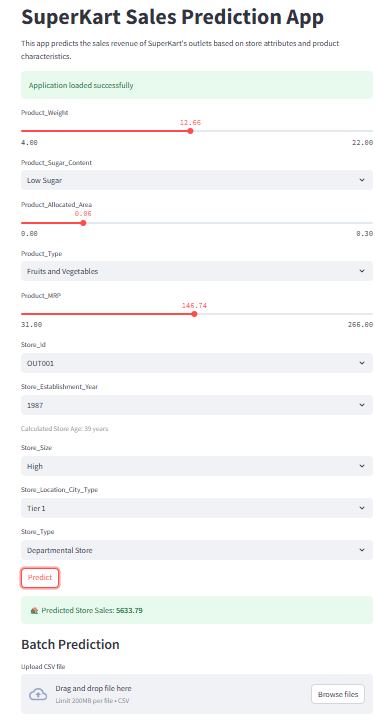

# **Actionable Insights and Business Recommendations**

## **Key Insights**

**EDA Insights**

- **Low sugar products** are the **most common** products in the dataset in the **Product_Sugar_Content** cateogry.

- **Fruits and Vegetables** form the **largest Product_Type** category in the dataset.

- **Medium Sized** stores located in **Tier 2** cities **dominate** the dataset.

- **Product_MRP** and **Product_Weight** show a **positive relationship** with **sales** indicating that high MRP and higher weight products tend to generate more sales.

- The **sales distribution** of **Product_Type** and **Product_Sugar_Content** is **similar** accross all categories indicating these variables have a **limited impact on sales**.

- The **store-related characteristics**, Store-Type and Store_Size have a **larger influence** on sales compared to **product-related** characteristics.

- A **one-to-one** relationship between **Store_ID** and **Store_Type** suggests that these two attributes capture similar information.

**Model Insights**

- A total of **four models** were generated:
    - Base Random Forest Regressor
    - Base XGBoost Regressor
    - Tuned Random Forest Regressor
    - Tuned XGBoost Regressor

- The **base models performed well** but showed **mild overfitting**.

- **Hyperparameter tuning** **reduced overfitting** but **worsened** the **performance** of Tuned Random Forest model compared to the base model.

- Although the **tuned XGBoost model** showed a **balance** between model **performance** and **generalization**, the **base Random Forest** model achieved the **highest test-set adjusted-R²** and the **lowest MAE, RMSE**, and **MAPE** values.

- Thus the **base Random Forest** model was selected as the **final model** for **deployment**.

- The selected **base Random Forest** model was successfully deployed as a web application through Flask API and Streamlit, enabling SuperKart to obtain real-time sales predictions.

## **Business Recommendations**

- SuperKart can integrate the deployed sales forecasting application to predict real-time sales and make informed decisions about inventory planning.

- Prioritize high MRP products by focusing on inventory management and promotional campaigns as product MRP shows a strong association with sales.

- Develop store-specific expansion and marketing strategies as store characteristics appear to have a higher impact on sales.

- Analyse the operations of high performing stores and see if similar strategies can be replicated across low performing stores.